# Two-compartment PK with Dynestyx defaults and NUTS

An IV bolus enters the central compartment. Drug exchanges between the central
amount $x_c$ and the peripheral amount $x_p$, and leaves through the central
compartment at rate $k_{10}$.

$$
\frac{d}{dt}
\begin{bmatrix}x_c\\x_p\end{bmatrix}
=
\begin{bmatrix}
-(k_{10}+k_{12}) & k_{21}\\
k_{12} & -k_{21}
\end{bmatrix}
\begin{bmatrix}x_c\\x_p\end{bmatrix},
\qquad
y_i \sim \mathcal{N}(x_c(t_i),\sigma^2).
$$

This synthetic example fixes $k_{10}$ and the observation noise. A tight
initial-state distribution centers the normalized dose at $(1,0)$. We fit
$k_{12}$ and $k_{21}$ from six central observations. The first post-dose
sample is at 1.2 minutes, after most of the fast exchange transient has
decayed.

In [1]:
import arviz_stats as azs
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist

import dynestyx as dsx
from dynestyx.inference.configs.mcmc import NUTSConfig
from dynestyx.inference.mcmc import MCMCInference

SEED = 0
simulation_key, nuts_key = jr.split(jr.PRNGKey(SEED))

K10 = 3.5  # per hour
TRUE_RATES = jnp.array([420.0, 140.0])  # k12 and k21 per hour
X0 = jnp.array([1.0, 0.0])
X0_SD = 1e-3
OBS_SD = 0.015
LOG_RATE_MIN = jnp.log(jnp.array([80.0, 30.0]))
LOG_RATE_MAX = jnp.log(jnp.array([1600.0, 600.0]))


def pk_dynamics(k12, k21):
    A = jnp.array([[-(K10 + k12), k21], [k12, -k21]])
    return dsx.DynamicalModel(
        initial_condition=dist.MultivariateNormal(
            X0, covariance_matrix=X0_SD**2 * jnp.eye(2)
        ),
        state_evolution=dsx.ContinuousTimeStateEvolution(
            drift=dsx.AffineDrift(A=A)
        ),
        observation_model=dsx.LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0]]), R=jnp.array([[OBS_SD**2]])
        ),
        control_dim=0,
    )


def pk_model(obs_times, obs_values, ctrl_times=None, ctrl_values=None):
    log_rates = numpyro.sample(
        "log_rates", dist.Uniform(LOG_RATE_MIN, LOG_RATE_MAX).to_event(1)
    )
    k12, k21 = jnp.exp(log_rates)
    return dsx.sample(
        "pk", pk_dynamics(k12, k21), obs_times=obs_times, obs_values=obs_values
    )

## Simulate the sparse observations

`dsx.simulate` selects the default ODE simulator for this model. The ODE
has a fast time constant of about 6.4 seconds and a slow time constant of
about 69 minutes at the simulated rates. The dense curve shows the simulated
central state. We keep one observation every 1.2 minutes, for six in total.

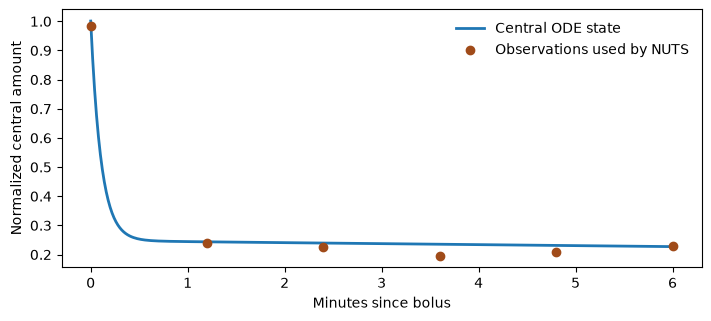

In [2]:
dynamics = pk_dynamics(*TRUE_RATES)
plot_times = jnp.linspace(0.0, 0.10, 301)  # hours
synthetic = dsx.simulate(dynamics, rng_key=simulation_key, predict_times=plot_times)
obs_times = plot_times[::60]
obs_values = synthetic.observations[0, ::60]

fig, ax = plt.subplots(figsize=(7, 3.1), layout="constrained")
ax.plot(60 * plot_times, synthetic.states[0, :, 0], lw=2, label="Central ODE state")
ax.scatter(
    60 * obs_times, obs_values[:, 0],
    color="#a04b19", zorder=3, label="Observations used by NUTS",
)
ax.set(xlabel="Minutes since bolus", ylabel="Normalized central amount")
ax.legend(frameon=False)
plt.show()

## Fit the exchange rates with NUTS

Leave `dsx.sample` unconfigured. In Dynestyx 0.8.1 it selects
`Discretizer(ODEFlowConfig())` and the Cuthbert ensemble Kalman filter for
this partially observed ODE. The default flow uses fixed-step Tsit5 with
$Delta t=10^{-3}$ hours. NUTS uses that filter's approximate likelihood,
with the default 30-member ensemble and fixed filter seed. The run specifies
the sampler backend and chain lengths. NUTS uses its default initialization
and target acceptance probability of 0.8.

The saved run used two sequential chains on one JAX device.

In [3]:
n_warmup, n_draws, n_chains = 250, 400, 2
config = NUTSConfig(
    num_warmup=n_warmup,
    num_samples=n_draws,
    num_chains=n_chains,
    mcmc_source="numpyro",
)
inference = MCMCInference(config, pk_model)
posterior = inference.run(nuts_key, obs_times, obs_values)
log_rates = np.asarray(posterior["log_rates"]).reshape(n_chains, n_draws, 2)
rates = np.exp(log_rates)
diagnostics = inference.get_diagnostics()

## Inspect the ridge

Once the fast transient decays, the central fraction is approximately
$k_{21}/(k_{12}+k_{21})$ when exchange is much faster than elimination.
Scaling both rates together leaves that fraction unchanged. In the joint
plot this gives a positively sloped ridge. Compare the spread in
$k_{12}/k_{21}$ with the spread in $\sqrt{k_{12}k_{21}}$ and check whether
the chains cover the same part of the ridge.

k12 (per hour)               345.76 [ 127.89, 1324.51]   R-hat 1.006   bulk ESS 92
k21 (per hour)               104.63 [  38.36,  390.96]   R-hat 1.006   bulk ESS 91
k12 / k21                      3.30 [   3.08,    3.54]   R-hat 1.000   bulk ESS 627
sqrt(k12 × k21) (per hour)   190.99 [  70.24,  721.95]   R-hat 1.007   bulk ESS 91
Rows report median [5%, 95%]. R-hat and ESS use log coordinates.
Divergences per chain [0 0]


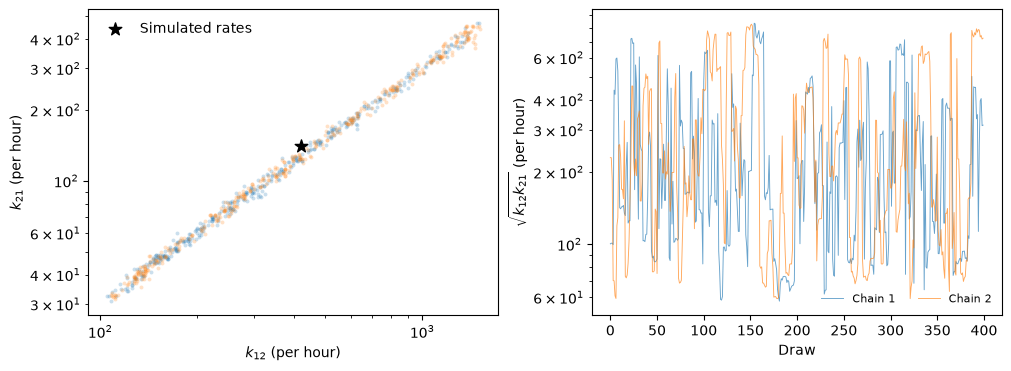

In [4]:
log_ratio = log_rates[..., 0] - log_rates[..., 1]
log_speed = log_rates.mean(axis=-1)
fig, (joint, trace) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for chain, chain_rates in enumerate(rates):
    joint.scatter(*chain_rates.T, s=8, alpha=0.23, linewidths=0)
    trace.plot(np.exp(log_speed[chain]), lw=0.65, alpha=0.68, label=f"Chain {chain + 1}")

joint.scatter(*TRUE_RATES, marker="*", color="black", s=90, label="Simulated rates")
joint.set(
    xscale="log", yscale="log",
    xlabel=r"$k_{12}$ (per hour)", ylabel=r"$k_{21}$ (per hour)",
)
joint.legend(frameon=False, loc="upper left")
trace.set(
    yscale="log", xlabel="Draw",
    ylabel=r"$\sqrt{k_{12}k_{21}}$ (per hour)",
)
trace.legend(frameon=False, ncols=2, fontsize=8)
plt.show()

for label, log_quantity in [
    ("k12 (per hour)", log_rates[..., 0]),
    ("k21 (per hour)", log_rates[..., 1]),
    ("k12 / k21", log_ratio),
    ("sqrt(k12 × k21) (per hour)", log_speed),
]:
    lower, median, upper = np.quantile(np.exp(log_quantity), [0.05, 0.50, 0.95])
    print(
        f"{label:27s} {median:7.2f} [{lower:7.2f}, {upper:7.2f}]"
        f"   R-hat {azs.rhat(log_quantity):.3f}"
        f"   bulk ESS {azs.ess(log_quantity, method='bulk'):.0f}"
    )
print("Rows report median [5%, 95%]. R-hat and ESS use log coordinates.")
print("Divergences per chain", np.asarray(diagnostics["num_divergences"]))

In the saved run, the 90% posterior interval for $k_{12}/k_{21}$ is 3.08–3.54, slightly above the simulated ratio of 3. The interval for $\sqrt{k_{12}k_{21}}$ spans 70–722 per hour. Both chains show the ridge, with zero divergences. The bulk ESS of about 91 for the geometric mean reflects slower exploration along the ridge.